In [16]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import joblib
import warnings
warnings.filterwarnings("ignore")



In [17]:

# 2. Load Dataset

df = pd.read_csv("/content/Mall_Customers.csv")

display(df.head())

print("\nDataset Shape:", df.shape)
df.info()



,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40



Dataset Shape: (200, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [18]:

# 3. Data Cleaning

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

df.drop_duplicates(inplace=True)

df.dropna(subset=[
    "Gender", "Age",
    "Annual Income (k$)",
    "Spending Score (1-100)"
], inplace=True)




Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

Duplicate Records: 0


In [19]:
# Standardize column names

df.rename(columns={
    "Genre": "Gender",
    "Annual Income (k$)": "Annual_Income",
    "Spending Score (1-100)": "Spending_Score"
}, inplace=True)

display(df.head())




,CustomerID,Gender,Age,Annual_Income,Spending_Score
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [20]:
# 4. Feature Engineering

def create_category(score):
    if score <= 40:
        return "Low"
    elif score <= 60:
        return "Medium"
    else:
        return "High"

df["Spending_Category"] = (
    df["Spending_Score"].apply(create_category)
)

print("\nSpending Category Distribution:")
print(df["Spending_Category"].value_counts())

# Save cleaned dataset

df.to_csv("Cleaned_Customer_Data.csv", index=False)






Spending Category Distribution:
Spending_Category
Medium    75
Low       63
High      62
Name: count, dtype: int64



Statistical Summary:


,CustomerID,Age,Annual_Income,Spending_Score
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


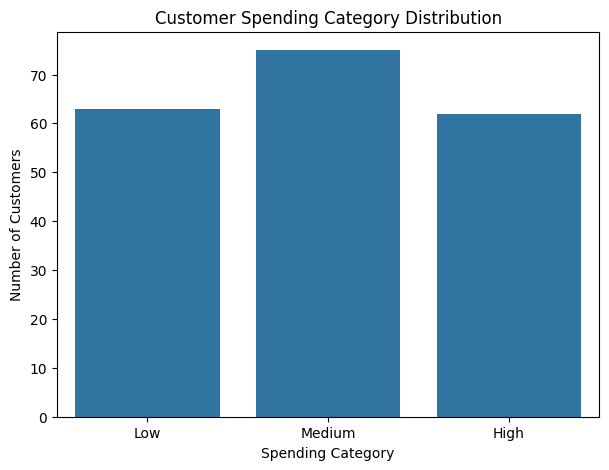

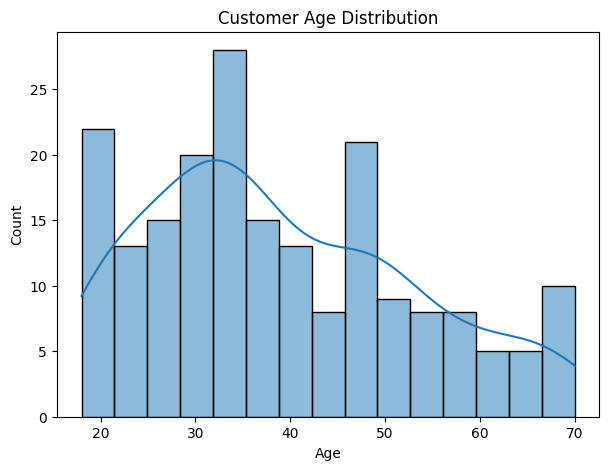

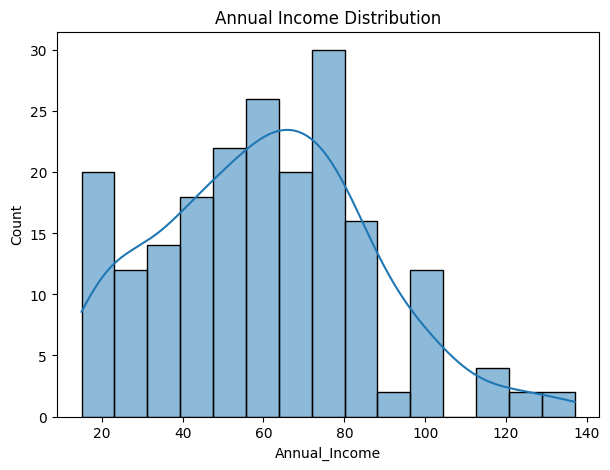

In [21]:
# 5. Exploratory Data Analysis

print("\nStatistical Summary:")
display(df.describe())

# Visualization 1: Spending Category

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="Spending_Category",
    order=["Low", "Medium", "High"]
)
plt.title("Customer Spending Category Distribution")
plt.xlabel("Spending Category")
plt.ylabel("Number of Customers")
plt.show()


# Visualization 2: Age Distribution

plt.figure(figsize=(7, 5))
sns.histplot(df["Age"], bins=15, kde=True)
plt.title("Customer Age Distribution")
plt.show()


# Visualization 3: Annual Income

plt.figure(figsize=(7, 5))
sns.histplot(df["Annual_Income"], bins=15, kde=True)
plt.title("Annual Income Distribution")
plt.show()




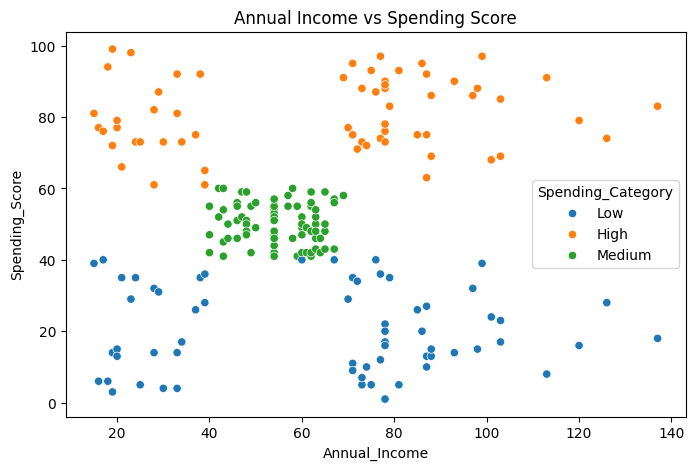

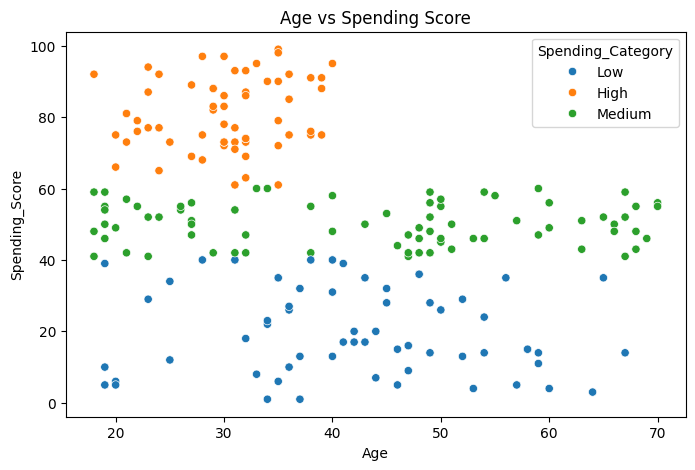

In [22]:
# Visualization 4: Income vs Spending Score

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Spending_Score",
    hue="Spending_Category"
)
plt.title("Annual Income vs Spending Score")
plt.show()


# Visualization 5: Age vs Spending Score

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Age",
    y="Spending_Score",
    hue="Spending_Category"
)
plt.title("Age vs Spending Score")
plt.show()




In [23]:
# 6. Prepare Data for Machine Learning

# Do not use CustomerID or Spending_Score as predictors.
# Spending_Category is derived from Spending_Score.

X = df[["Gender", "Age", "Annual_Income"]]
y = df["Spending_Category"]

categorical_features = ["Gender"]
numerical_features = ["Age", "Annual_Income"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))




Training Records: 160
Testing Records: 40


In [24]:
# 7. Build Machine Learning Models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("\nModel:", name)
    print(classification_report(
        y_test, y_pred,
        zero_division=0
    ))






Model: Logistic Regression
              precision    recall  f1-score   support

        High       0.61      0.92      0.73        12
         Low       0.60      0.46      0.52        13
      Medium       0.67      0.53      0.59        15

    accuracy                           0.62        40
   macro avg       0.63      0.64      0.62        40
weighted avg       0.63      0.62      0.61        40


Model: Random Forest
              precision    recall  f1-score   support

        High       0.62      0.83      0.71        12
         Low       0.70      0.54      0.61        13
      Medium       1.00      0.93      0.97        15

    accuracy                           0.78        40
   macro avg       0.78      0.77      0.76        40
weighted avg       0.79      0.78      0.77        40




Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.625,0.628333,0.625,0.611787
1,Random Forest,0.775,0.790000,0.775,0.774181


<Figure size 800x500 with 0 Axes>

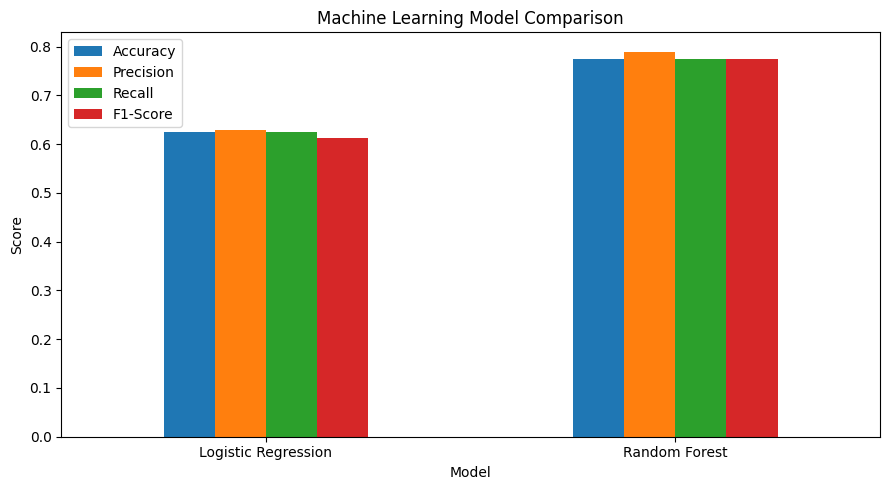

In [25]:
# 8. Model Comparison

comparison = pd.DataFrame(results)

print("\nModel Performance Comparison:")
display(comparison)

comparison.to_csv("Model_Comparison.csv", index=False)

plt.figure(figsize=(8, 5))

comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(9, 5))

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()





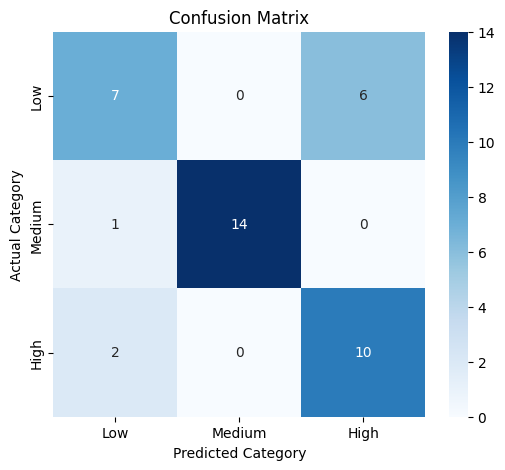

In [26]:
# 9. Confusion Matrix

best_model_name = comparison.sort_values(
    by="F1-Score", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

labels = ["Low", "Medium", "High"]

cm = confusion_matrix(
    y_test, y_pred,
    labels=labels
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.show()




Feature Importance:


,Feature,Importance
1,num__Annual_Income,0.591473
0,num__Age,0.388342
3,cat__Gender_Male,0.010834
2,cat__Gender_Female,0.009351


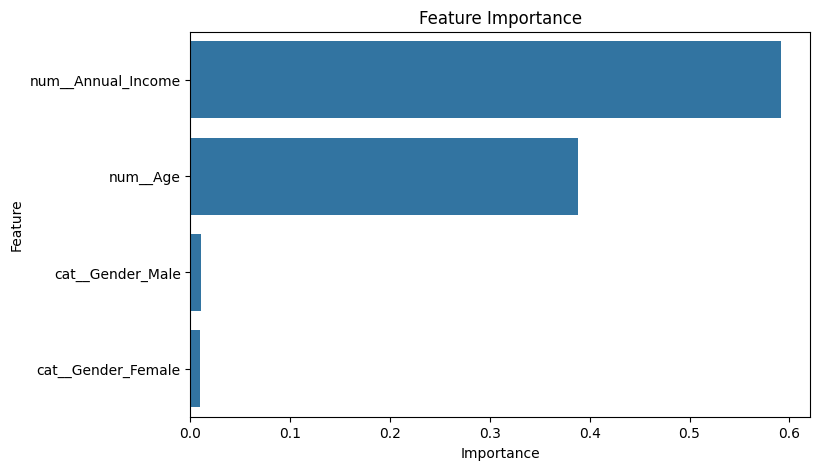

In [27]:

# 10. Feature Importance (Random Forest)

rf_model = trained_models["Random Forest"]

feature_names = (
    rf_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

importance = rf_model.named_steps[
    "classifier"
].feature_importances_

feature_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
}).sort_values(
    by="Importance", ascending=False
)

print("\nFeature Importance:")
display(feature_df)

feature_df.to_csv("Feature_Importance.csv", index=False)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=feature_df,
    x="Importance",
    y="Feature"
)
plt.title("Feature Importance")
plt.show()




In [28]:
# 11. Customer Spending Prediction

def predict_customer(gender, age, annual_income):

    customer = pd.DataFrame({
        "Gender": [gender],
        "Age": [age],
        "Annual_Income": [annual_income]
    })

    prediction = best_model.predict(customer)

    return prediction[0]


# Example Customer

result = predict_customer(
    gender="Male",
    age=25,
    annual_income=50
)

print("\nPredicted Spending Category:", result)





Predicted Spending Category: Medium


In [29]:
# 12. Save Best Model

joblib.dump(
    best_model,
    "Customer_Spending_Model.pkl"
)

print("\nBest Model:", best_model_name)



Best Model: Random Forest
